# From Model to Table - Analyzing Segmentation Quality

## 1. Imports and model loading

In [1]:
# !pip install cellpose[gui]
# !pip install pycocotools

from pathlib import Path
import tifffile
import warnings
warnings.simplefilter('ignore')

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle, Patch

from scipy.optimize import linear_sum_assignment
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

import torch
from tqdm import tqdm

from skimage.measure import regionprops, regionprops_table
from scipy.ndimage import distance_transform_edt, gaussian_filter, laplace, convolve
from skimage.segmentation import find_boundaries

from pycocotools.coco import COCO
from cellpose import models, io
from cellpose import metrics as cp_metrics

model = models.CellposeModel(pretrained_model="cpsam_v2", device=torch.device('mps'))


## 2. Inference

In [2]:
def coco_to_instance_mask(
    coco: COCO,
    image_id: int,
    dtype=np.uint16) -> np.ndarray:
    """
    A helper to convert COCO annotation into a integer mask
    """

    img_info = coco.loadImgs([image_id])[0]
    h, w = img_info["height"], img_info["width"]

    mask = np.zeros((h, w), dtype=dtype)

    annotations = coco.loadAnns(coco.getAnnIds(imgIds=[image_id]))

    for cell, annotation in enumerate(annotations, start=1):
        cell_mask = coco.annToMask(annotation).astype(bool)

        mask[cell_mask] = cell

    
    return mask

def inference(model: torch.nn.Module,
              path_to_image: str | Path,
              path_to_mask: str | Path) -> tuple[np.ndarray]:
    """
    Inference from the model

    Provide a paths (as Path or str) to the input RGB image and to the 
    true masks image

    Returns:
        tuple[np.ndarray]: original RGB image, true masks as np.array, predicted masks as np.array
    """

    if isinstance(path_to_image, str):
        path_to_image = Path(path_to_image)
    if isinstance(path_to_mask, str):
        path_to_mask = Path(path_to_mask)

    # Read the image and masks
    image = io.imread(path_to_image)
    true_cells = io.imread(path_to_mask)

    # Compute the prediction
    predicted_cells, _, _ = model.eval(image)

    return image, true_cells, predicted_cells



## 3. Mapping Predictions to True Cells

In [4]:
def create_cell_dataframe(
    true_cells: np.ndarray,
    groups: pd.DataFrame,
    pairs: pd.DataFrame,
    assignments: pd.DataFrame,
    match_iou: float = 0.5,
    ) -> pd.DataFrame:
    """
    Every row of the ouput is for a single true cell, its shape, descriptors and the
    estimated quality of predictions
    """
    properties = ["label", "area", "bbox", "centroid", "perimeter", "eccentricity", "solidity", "extent",
                  "orientation", "axis_major_length", "axis_minor_length", "equivalent_diameter_area"]

    cells = pd.DataFrame(regionprops_table(true_cells, properties=properties))

    # some better names for certain descriptors
    cells = cells.rename(columns={
        "label": "true_id",
        "area": "pixel_area",
        "bbox-0": "min_x",
        "bbox-1": "min_y",
        "bbox-2": "max_x",
        "bbox-3": "max_y",
        "centroid-0": "centroid_x",
        "centroid-1": "centroid_y",
        "axis_major_length": "major_axis_length",
        "axis_minor_length": "minor_axis_length",
        "equivalent_diameter_area": "equivalent_diameter",
    })


    cells["aspect_ratio"] = np.divide(cells["major_axis_length"], cells["minor_axis_length"].replace(0, np.nan))
    cells["circularity"] = np.divide(4 * np.pi * cells["pixel_area"], cells["perimeter"].replace(0, np.nan) ** 2)
    cells["pseudo_radius"] = np.sqrt(cells["pixel_area"] / np.pi)

    # Seraching what graph-derived group each true cell belongs to
    group_records = []
    for group_id, group in groups.iterrows():
        for true_id in group["true_ids"]:
            group_records.append({
                "true_id": int(true_id),
                "group_id": int(group_id),
                "group_type": group["type"], 
                "associated_pred_ids": list(group["predicted_ids"]),
                "n_associated_pred": len(group["predicted_ids"]),
                "n_associated_true": len(group["true_ids"]),
            })

    group_df = pd.DataFrame(group_records, columns=["true_id", "group_id", "group_type", "associated_pred_ids", "n_associated_pred", "n_associated_true"])
    cells = cells.merge(group_df, on="true_id", how="left", validate="one_to_one")

    # Add booelan columns for convience later
    for group_name in ["matched", "split", "merged", "complex", "missed"]:
        cells[group_name] = (cells["group_type"] == group_name)

    # Try to find best match by linear sum optimization
    if not pairs.empty:
        best_pairs = pairs.sort_values("iou", ascending=False).drop_duplicates(subset="true_id")[["true_id", "predicted_id", "iou", "overlap"]]
        best_pairs = best_pairs.rename(columns={"predicted_id": "best_associated_pred_id", "iou": "best_associated_iou","overlap": "best_associated_overlap"})
        cells = cells.merge(best_pairs, on="true_id", how="left", validate="one_to_one")
    else:
        cells["best_associated_pred_id"] = pd.nan
        cells["best_associated_iou"] = np.nan
        cells["best_associated_overlap"] = np.nan

    # Also add IOU score for the best found match
    assigned = assignments.rename(columns={"predicted_id": "assigned_pred_id", "iou": "assigned_iou"})
    cells = cells.merge(assigned, on="true_id", how="left", validate="one_to_one")
    cells["is_TP"] = (cells["assigned_iou"] >= match_iou)


    cells["assigned_pred_id"] = cells["assigned_pred_id"].astype('Int64')
    cells["best_associated_pred_id"] = (cells["best_associated_pred_id"].astype('Int64'))
    cells["group_id"] = cells["group_id"].astype('Int64')
    return cells.sort_values("true_id").reset_index(drop=True)


def map_cell_instances(
    true_cells: np.ndarray,
    predicted_cells: np.ndarray,
    min_overlap: float = 0.1,
    match_iou: float = 0.5,
) -> dict:
    """
    Map ground-truth and predicted cell instances.

    true_cells, predicted_cells: integer masks
    min_overlap: minimum intersection to consider instances related
    match_iou: minimum Jaccard score to call a match

    Returns a dict
        groups: pd.DataFrame with groups 'matched', 'split', 'merged', 'complex', 'missed', 'artifact'
        pairs: pd.DataFrame with intersections for pairs
        matches: pd.DataFrame with one-to-one pairs
    """

    if true_cells.shape != predicted_cells.shape:
        raise ValueError( f"Masks must have the same shape, but {true_cells.shape} != {predicted_cells.shape}")

    if not (0 < min_overlap <= 1 and 0 < match_iou <= 1):
        raise ValueError("min_overlap and match_iou must be in (0, 1]")

    if np.any(true_cells < 0) or np.any(predicted_cells < 0):
        raise ValueError("Instance labels cannot be negative")

    # Changing the mapping:
    # true_inv and pred_inv are of the same shape as true_cells / predicted_cells
    # but now masks are enumerated by the order of their encounter
    # in a flattened array, while _ids contain the old numbers

    true_ids, true_inv = np.unique(true_cells, return_inverse=True)
    pred_ids, pred_inv = np.unique(predicted_cells, return_inverse=True)

    n_true, n_pred = len(true_ids), len(pred_ids)

    # Pixel-wise confusion matrix:
    # true_inv * n_pred + pred_inv gives every pair of (true cell, predicted cell) a unique integer code
    # bincount counts these unique combinations pixel-wise
    # minlength=n_true * n_pred assures that even empty combinations are not skipped and assigned 0 instead
    # .reshape(n_true, n_pred) makes a matrix of shape (N of true cells, N of predicted cells), where each entry
    # ij shows the number of pixels shared by true cell i and predicted cell j
    intersection = np.bincount((true_inv * n_pred + pred_inv).flatten(), minlength=n_true * n_pred).reshape(n_true, n_pred)

    # Count total areas of every true cell and every predicted cell
    true_area = intersection.sum(axis=1)
    pred_area = intersection.sum(axis=0)

    # Getting non-zero indices
    # in principle can be just np.arange(1, len(true_ids)) but just in case background is not the first entry:
    true_idx = np.flatnonzero(true_ids != 0)
    pred_idx = np.flatnonzero(pred_ids != 0)

    # Exclude background
    # np.ix_(true_idx, pred_idx) creates a mesh of non-background indices
    intersection = intersection[np.ix_(true_idx, pred_idx)]
    true_area = true_area[true_idx]
    pred_area = pred_area[pred_idx]

    # Union for Jaccard:
    # Count of true pixel + Count of predicted pixels - their intersection
    union = true_area[:, None] + pred_area[None, :] - intersection

    # Jaccard:
    # intesection / union, with defence and zero division (however, not really necessary)
    iou = np.divide(intersection, union, out=np.zeros_like(intersection, dtype=float), where=union > 0)

    # Overlap = intersection / min(true pixel count, predicted pixel count) - symmetric idea
    overlap = np.divide(intersection,
                        np.minimum(true_area[:, None], pred_area[None, :]),
                        out=np.zeros_like(intersection, dtype=float),
                        where=(true_area[:, None] > 0) & (pred_area[None, :] > 0))

    # Identify what true and predicted segments are at least somehow related:
    # 1. Have intersecting pixels
    # 2. Have at least certain level of overlap
    adjacency = (intersection > 0) & (overlap >= min_overlap)

    # Drop background from original ids
    true_ids = true_ids[true_idx]
    pred_ids = pred_ids[pred_idx]

    # Get connections between related segments
    rows, cols = np.where(adjacency)

    # Store related pairs
    pairs = pd.DataFrame([
        {
            "true_id": int(true_ids[i]),
            "predicted_id": int(pred_ids[j]),
            "intersection": int(intersection[i, j]),
            "iou": float(iou[i, j]),
            "overlap": float(overlap[i, j]),
        }
        for i, j in zip(rows, cols)
    ])


    n_true = len(true_ids)
    n_pred = len(pred_ids)

    # Create a bipartite graph
    # total number of nodes = n_true + n_pred
    graph = np.zeros((n_true + n_pred, n_true + n_pred), dtype=np.uint8)

    # Put binary adjececy matrix into zones connecting true and predicted segments
    graph[:n_true, n_true:] = adjacency
    graph[n_true:, :n_true] = adjacency.T

    # Extract connected subgraphs using scipy.sparse.csgraph routine
    # labels is an array which assigns every node its subgraph index
    n_subgraphs, labels = connected_components(csr_matrix(graph), directed=False)

    # Classify subgraphs
    groups = []

    for subgaph in np.unique(labels):


        true_members = true_ids[labels[:n_true] == subgaph].astype(int).tolist()
        pred_members = pred_ids[labels[n_true:] == subgaph].astype(int).tolist()

        n_t = len(true_members)
        n_p = len(pred_members)

        if n_t == 1 and n_p == 1:
            category = "matched"
        elif n_t == 1 and n_p > 1:
            category = "split"
        elif n_t > 1 and n_p == 1:
            category = "merged"
        elif n_t > 1 and n_p > 1:
            category = "complex"
        elif n_t == 1 and n_p == 0:
            category = "missed"
        elif n_t == 0 and n_p == 1:
            category = "artifact"
        else:
            raise RuntimeError("Unexpected subgaph structure.")

        groups.append({
            "type": category,
            "true_ids": true_members,
            "predicted_ids": pred_members,
            "n_true": n_t,
            "n_predicted": n_p,
        })

    # Store subgraphs ain a dataframe
    groups = pd.DataFrame(groups)

    # Now registering exact matches:

    # using scipy optimization linear_sum_assignment to choose the best pair matches,
    # so that it maximizes the sum of Jaccard scores, while using every row and column
    # at most once (now adjusted to match the official pipeline)
    # Below:
    #   assignments: stand for complete dataframe of assignments
    #   matches: a subframe with only assignments with enough confidence
    if n_true and n_pred:
        n_min = min(n_true, n_pred)

        costs = (
            -(iou >= match_iou).astype(float)
            - iou / (2 * n_min)
        )

        r, c = linear_sum_assignment(costs)
    else:
        r = np.array([], dtype=int)
        c = np.array([], dtype=int)

    assignments = pd.DataFrame(
        [
            {
                "true_id": int(true_ids[i]),
                "predicted_id": int(pred_ids[j]),
                "iou": float(iou[i, j]),
            }
            for i, j in zip(r, c)
        ],
        columns=["true_id", "predicted_id", "iou"]
    )

    matches = assignments[
        assignments["iou"] >= match_iou
    ].copy()

    # NOTE: related subgraphs from bipartite graph connected components also return 'matched' but for groupes that has exctaly 1 
    # true cell and one predicted cell and has at least certain overlep (usually rather small). In theory, I could have used just
    # a match threshold there and call them matches. But I would overlook situations with, e.g. 2 predicted cells related to 1 true cell
    # where one of the predictions overlap with the true one heavily, and another one - weakly. Logically, the true one and heavily overlapping prediction
    # should also be a one-to-one match, so, I use a separate optimization algorithm for matches.


    # Finally, adding dataframe of individual cells:
    cells = create_cell_dataframe(
        true_cells=true_cells,
        groups=groups,
        pairs=pairs,
        assignments=assignments,
        match_iou=match_iou
    )

    if n_true and n_pred:
        best = np.argmax(iou, axis=1)
        best_ious = pd.DataFrame({"true_id": true_ids, "best_pred_id": pred_ids[best], "best_iou": iou[np.arange(n_true), best]})
    else:
        best_ious = pd.DataFrame(columns=["true_id", "best_pred_id", "best_iou"])

    cells = cells.merge(best_ious, on="true_id", how="left")
    cells["best_iou"] = cells["best_iou"].fillna(0.0)
    
    return {
        "groups": groups,
        "pairs": pairs,
        "matches": matches,
        "cells": cells,
        "iou_raw": iou,
        "inter_raw": intersection,
        "match_iou": match_iou,
        "min_overlap": min_overlap,
    }

## 4. Aggregating Evaluation Metrics per Instance

In [5]:
def cellpose_ap(iou: np.ndarray, threshold: float) -> float:
    """
    Cellpose Average Precision (from official code)
    """

    n_true, n_pred = iou.shape

    if n_true == 0 or n_pred == 0:
        tp = 0
    else:
        n_min = min(n_true, n_pred)

        cost = (-(iou >= threshold).astype(float) - iou / (2 * n_min))
        rows, cols = linear_sum_assignment(cost)
        tp = np.count_nonzero(iou[rows, cols] >= threshold)

    fp = n_pred - tp
    fn = n_true - tp

    denom = tp + fp + fn

    return tp / denom if denom else np.nan

def cellpose_aji(
    true_cells: np.ndarray,
    predicted_cells: np.ndarray,
    iou: np.ndarray,
    inter: np.ndarray,
) -> float:
    """
    Cellpose official AJI
    """

    foreground_union = np.count_nonzero((true_cells > 0) | (predicted_cells > 0))

    if foreground_union == 0:
        return np.nan

    n_true, n_pred = iou.shape

    if n_true == 0 or n_pred == 0:
        return 0.0

    n_min = min(n_true, n_pred)

    # Official threshold is 0.5
    costs = (-(iou >= 0.5).astype(float) - iou / (2 * n_min))
    r, c = linear_sum_assignment(costs)

    intersection_sum = inter[r, c].sum()

    return float(intersection_sum / foreground_union)

def aggregate_cell_results(
    true_cells: np.ndarray,
    predicted_cells: np.ndarray,
    result: dict[str, pd.DataFrame],
    image_id: str | int | None = None,
    dataset: str | None = None,
    model: str | None = None,
) -> pd.DataFrame:
    """
    Aggregate cell instance segmentation results into one row.
    Returns a pd.DataFrame
    """

    groups = result["groups"]
    matches = result["matches"]

    # Unique IDs without background
    n_true = len(np.unique(true_cells)) - int(np.any(true_cells == 0))
    n_pred = len(np.unique(predicted_cells)) - int(np.any(predicted_cells == 0))

    # Conventional metrics:

    # TP, FP, FN
    tp = len(matches)
    fp = n_pred - tp
    fn = n_true - tp

    # PREC, RECALL
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan

    # F1
    f1 = (2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0 if n_true + n_pred > 0 else np.nan)

    # Average precision at thesholds
    iou = result["iou_raw"]
    ap50 = cellpose_ap(iou=iou, threshold=0.5)
    ap75 = cellpose_ap(iou=iou, threshold=0.75)
    ap90 = cellpose_ap(iou=iou, threshold=0.9)

    # Boundary metrics
    scales = [0.5, 0.75, 0.9]

    ## There is a problem that official metric expects a batch of as an input, so:
    b_precision, b_recall, b_f1 = cp_metrics.boundary_scores([true_cells], [predicted_cells], scales=scales)
    b_prec_50, b_prec_75, b_prec_90 = b_precision[:, 0]
    b_rec_50, b_rec_75, b_rec_90 = b_recall[:, 0]
    b_f1_50, b_f1_75, b_f1_90 = b_f1[:, 0]


    # Average similarity measures

    # Mean Jaccard score in TP, median Jaccard score in TP, mean Dice score in TP
    if tp:
        ious = matches["iou"].to_numpy(dtype=float)
        dices = 2 * ious / (1 + ious)

        mean_iou = float(ious.mean())
        median_iou = float(np.median(ious))
        mean_dice = float(dices.mean())
    else:
        mean_iou = np.nan
        median_iou = np.nan
        mean_dice = np.nan

    # Count group categories
    categories = groups["type"].value_counts() if len(groups) else pd.Series(dtype=int)

    # Overall pixel metrics: Jaccard, Dice
    # (Just how many pixels are attributed to cell segments overall in true masks and predicted masks -
    # regardless the matches)
    true_fg = true_cells != 0
    pred_fg = predicted_cells != 0

    fg_intersection = np.count_nonzero(true_fg & pred_fg)
    fg_union = np.count_nonzero(true_fg | pred_fg)

    foreground_iou = (fg_intersection / fg_union if fg_union else np.nan)
    fg_sum = np.count_nonzero(true_fg) + np.count_nonzero(pred_fg)
    foreground_dice = (2 * fg_intersection / fg_sum if fg_sum else np.nan)

    # Aggregated Jaccard Index AJI:
    # matched instance intersections / corresponding union
    # plus the areas of all unmatched instances.
    if n_true + n_pred:

        # Make dicts of IDs -> Areas
        true_ids, true_area = np.unique(true_cells[true_cells > 0], return_counts=True)
        pred_ids, pred_area = np.unique(predicted_cells[predicted_cells > 0], return_counts=True)
        true_areas = dict(zip(true_ids, true_area))
        pred_areas = dict(zip(pred_ids, pred_area))

        matched_true = set()
        matched_pred = set()

        aji_intersection = 0
        aji_union = 0

        # Iterate over paired matches
        for row in matches.itertuples(index=False):
            t_id = row.true_id
            p_id = row.predicted_id
            iou = row.iou

            # Restoring intersection from areas and Jaccard
            # intersection = Jaccard * (area_true + area_pred) / (1 +Jaccard)
            intersection = (iou * (true_areas[t_id] + pred_areas[p_id]) / (1 + iou))

            # Restoring union
            union = true_areas[t_id] + pred_areas[p_id] - intersection

            # Summing up
            aji_intersection += intersection
            aji_union += union

            matched_true.add(t_id)
            matched_pred.add(p_id)

        # Also adding areas that do not belong to matched pairs (they are without intersections)
        aji_union += sum(area for tid, area in true_areas.items() if tid not in matched_true)
        aji_union += sum(area for pid, area in pred_areas.items() if pid not in matched_pred)

        # AJI:
        aji = aji_intersection / aji_union if aji_union else np.nan

        # Official AJI
        aji_offcial = cellpose_aji(
            true_cells=true_cells,
            predicted_cells=predicted_cells,
            iou=result['iou_raw'],
            inter=result['inter_raw']
        )
    else:
        aji = np.nan
        aji_offcial = np.nan

    def count(category):
        return int(categories.get(category, 0))

    row = {

        "image_id": image_id,
        "dataset": dataset,
        "model": model,

        "n_true": n_true,
        "n_predicted": n_pred,
        "count_error": n_pred - n_true,

        # Standard
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "ap50": ap50,
        "ap75": ap75,
        "ap90": ap90,

        # Boundary metrics
        "b_prec_50": b_prec_50,
        "b_prec_75": b_prec_75,
        "b_prec_90": b_prec_90,
        "b_rec_50": b_rec_50,
        "b_rec_75": b_rec_75,
        "b_rec_90": b_rec_90,
        "b_f1_50": b_f1_50,
        "b_f1_75": b_f1_75,
        "b_f1_90": b_f1_90,

        # Mean Jac and Dice
        "mean_iou": mean_iou,
        "median_iou": median_iou,
        "mean_dice": mean_dice,

        # Global
        "foreground_iou": foreground_iou,
        "foreground_dice": foreground_dice,
        "aji_custom": aji,
        "aji_official": aji_offcial,

        # Counts of groups
        "n_matched_groups": count("matched"),
        "n_split_groups": count("split"),
        "n_merged_groups": count("merged"),
        "n_complex_groups": count("complex"),
        "n_missed_groups": count("missed"),
        "n_artifact_groups": count("artifact"),

        # Hyperparameters
        "match_iou": result["match_iou"],
        "min_overlap": result["min_overlap"],
    }

    return pd.DataFrame([row])

## 5. Analysis of Original RGB Image

In [6]:
def analyze_image(
    image: np.ndarray,
    true_cells: np.ndarray | None = None,
    image_id: str | int | None = None,
    dataset: str | None = None) -> pd.DataFrame:
    """
    Image descriptors

    image: actual image
    true_cells: integer mask with true segments
    image_id: image identifier
    dataset: dataset identifier

    Returns
    -------
    pd.DataFrame: df of descriptors
    """

    h, w = image.shape[:2]
    n_channels = 1 if image.ndim == 2 else image.shape[-1]


    dtype = image.dtype
    bit_depth = dtype.itemsize * 8

    row = {
        "image_id": image_id,
        "dataset": dataset,
        "height": h,
        "width": w,
        "aspect_ratio": w / h,
        "n_pixels": h * w,
        "channels": n_channels,
        "dtype": str(dtype),
        "bit_depth": bit_depth,
    }

    # Convert to grayscale
    img = image.astype(np.float32)

    if image.ndim == 2:
        gray = img
    elif n_channels == 3:

        # Standard luminance definition:
        gray = (0.2126 * img[..., 0] + 0.7152 * img[..., 1] + 0.0722 * img[..., 2])
    else:
        gray = img.mean(axis=-1)

    # Percentiles
    p01, p99 = np.percentile(gray, [1, 99])

    row.update({
        "intensity_mean": float(gray.mean()),
        "intensity_std": float(gray.std()),
        "intensity_p01": float(p01),
        "intensity_p99": float(p99),
        "contrast": float(p99 - p01),
    })

    # Using iinfo to unify different bit depths => gray_norm
    if np.issubdtype(dtype, np.integer):
        info = np.iinfo(dtype)
        gray_norm = (gray - info.min) / (info.max - info.min)
    else:
        l, h = gray.min(), gray.max()
        gray_norm = (gray - l) / (h - l) if h > l else np.zeros_like(gray)

    # variance of Laplacian
    lap = laplace(gray_norm)

    # Estimatiing noise against Gaussian blurrign
    smooth = gaussian_filter(gray_norm, sigma=1.0)
    residual = gray_norm - smooth

    row.update({
        "laplacian_variance": float(lap.var()),
        "noise_estimate": float(residual.std()),
    })

    # Count cells in the true mask (if provided)
    if true_cells is not None:
        labels, counts = np.unique(true_cells[true_cells != 0], return_counts=True)

        n_cells = len(labels)
        foreground_pixels = int(counts.sum())

        mean_area = float(counts.mean()) if n_cells else np.nan
        median_area = float(np.median(counts)) if n_cells else np.nan

        area_cv = float(counts.std() / counts.mean()) if n_cells and counts.mean() > 0 else np.nan

        row.update({
            "n_cells": n_cells,
            "cell_density": n_cells / (h * w) * 1e6,
            "foreground_fraction": foreground_pixels / (h * w),
            "mean_cell_area": mean_area,
            "median_cell_area": median_area,
            "cell_area_cv": area_cv,
        })

    return pd.DataFrame([row])

## 6. Plotting

In [7]:
def plot_cell_results(
    image: np.ndarray,
    true_cells: np.ndarray,
    predicted_cells: np.ndarray,
    result: dict,
    summary=None,
    show_ids: bool = True,
    show_boxes: bool = True,
    alpha: float = 0.45,
    figsize: tuple = (18, 7),
):
    """
    Visualize instance segmentation quality

    Parameters
    ----------
    image : ndarray
        original image
    true_cells, predicted_cells : ndarray
        masks with background = 0.
    result : dict
        output from map_cell_instances function
    summary : pd.DataFrame or dict, optional
        aggregate_cell_results
    show_ids : bool
        show segment ids
    show_boxes : bool
        draw boxes about suspicious groups of segments
    alpha : float
        opacity
    figsize : tuple
        dimensions

    Returns
    -------
    fig, axes
    """

    if true_cells.shape != predicted_cells.shape:
        raise ValueError(f"Instance masks must match in shape, {true_cells.shape} != {predicted_cells.shape}")

    if image.shape[:2] != true_cells.shape:
        raise ValueError(f"Image and masks must natch in shape, {image.shape[:2]} != {true_cells.shape}")

    # Color code for suspicious groups
    colors = {
        "matched":  "#35A853",   # g
        "split":    "#3288DB",   # b
        "merged":   "#F39C35",   # o
        "complex":  "#D94BC8",   # m
        "missed":   "#E34B4B",   # r
        "artifact": "#8D63D2",   # p
    }

    descriptions = {
        "matched":  f"One-to-one ({len(result['groups'][result['groups']['type'] == 'matched'])})",
        "split":    f"Split ({len(result['groups'][result['groups']['type'] == 'split'])})",
        "merged":   f"Merged ({len(result['groups'][result['groups']['type'] == 'merged'])})",
        "complex":  f"Complex ({len(result['groups'][result['groups']['type'] == 'complex'])})",
        "missed":   f"Missed ({len(result['groups'][result['groups']['type'] == 'missed'])})",
        "artifact": f"Artifact ({len(result['groups'][result['groups']['type'] == 'artifact'])})",
    }

    rgb = image.astype(np.uint8)
    
    # Create category mappings

    true_categories = {}
    pred_categories = {}
    group_boxes = []

    # Iterate over groups and store what segment ID is in each category
    for group in result["groups"].itertuples(index=False):
        category = group.type

        for t_id in group.true_ids:
            true_categories[int(t_id)] = category

        for p_id in group.predicted_ids:
            pred_categories[int(p_id)] = category

        if category != "matched":
            group_boxes.append(group)

    # Region descriptors for annotation and boxes
    true_regions = {r.label: r for r in regionprops(true_cells)}
    pred_regions = {r.label: r for r in regionprops(predicted_cells)}

    def create_overlay(mask, categories):
        """Create RGBA overlay for instance categories."""

        overlay = np.zeros((*mask.shape, 4), dtype=np.float32)

        for instance_id, category in categories.items():
            pixels = mask == instance_id

            overlay[pixels, :3] = to_rgb(colors[category])
            overlay[pixels, 3] = alpha

        return overlay

    def draw_instance_ids(ax, regions, prefix):
        """Annotate with number."""

        for instance_id, region in regions.items():

            y, x = region.centroid

            ax.text(x, y, f"{prefix}{instance_id}", ha="center", va="center", fontsize=7,
                    color="white", fontweight="bold", bbox={"facecolor": "black", "alpha": 0.5, "edgecolor": "none", "pad": 1})

    def draw_group_boxes(ax, group, regions, ids):

        """Draw a box around instances."""

        selected = [regions[i] for i in ids if i in regions]

        if not selected:
            return

        min_row = min(r.bbox[0] for r in selected)
        min_col = min(r.bbox[1] for r in selected)
        max_row = max(r.bbox[2] for r in selected)
        max_col = max(r.bbox[3] for r in selected)

        pad = 3

        rect = Rectangle((min_col - pad, min_row - pad), max_col - min_col + 2 * pad, max_row - min_row + 2 * pad,
                        fill=False, edgecolor=colors[group.type], linewidth=1.5, linestyle="-", )

        ax.add_patch(rect)

    # Plots

    fig, axes = plt.subplots(1, 3, figsize=figsize, sharex=True, sharey=True, constrained_layout=True)
    ax_input, ax_true, ax_pred = axes
    
    # Show original RGB on every ax
    for i, ax in enumerate(axes):
        ax.imshow(rgb, alpha=1.0 if i == 0 else 0.4)
        ax.set_axis_off()

    # Find perimeter boundary for true and predicted segments
    true_edges = find_boundaries(true_cells, mode="inner")
    pred_edges = find_boundaries(predicted_cells, mode="inner")

    true_boundary_overlay = np.zeros((*true_cells.shape, 4))
    pred_boundary_overlay = np.zeros((*predicted_cells.shape, 4))

    # Set colors
    true_boundary_overlay[true_edges] = [0, 1, 0, 0.9]
    pred_boundary_overlay[pred_edges] = [1, 0.2, 0.2, 0.9]

    # Plot boundaries
    ax_input.imshow(true_boundary_overlay)
    ax_input.imshow(pred_boundary_overlay)

    # Create filled overlays for segments in true and pred axes
    ax_true.imshow(create_overlay(true_cells, true_categories))
    ax_pred.imshow(create_overlay(predicted_cells, pred_categories))

    # Annotate IDs if required
    if show_ids:
        draw_instance_ids(ax_true, true_regions, "T")
        draw_instance_ids(ax_pred, pred_regions, "P")

    # Draw bounding boxes for suspicious groups
    if show_boxes:
        for group in group_boxes:
            draw_group_boxes(ax_true, group, true_regions, group.true_ids)
            draw_group_boxes(ax_pred, group, pred_regions, group.predicted_ids)

    # Titles
    ax_input.set_title("Original image\nGreen: Labels / Red: Predictions")
    ax_true.set_title(f"True Labels ({len(true_regions)} cells)")
    ax_pred.set_title(f"Predictions ({len(pred_regions)} cells)")

    if summary is not None:
        row = summary.iloc[0]
        title = (f"Cellpose Segmentation | " +  f"F1: {row['f1']:.3f} | " +  f"Mean IoU: {row['mean_iou']:.3f} | " + f"AJI: {row['aji_official']:.3f}")
    else:
        title = "Cellpose Instance Segmentation Quality Analysis"

    fig.suptitle(title, fontsize=14, fontweight="bold")

    # Create lagend
    legend = [Patch(facecolor=color, edgecolor="none", label=descriptions[category])
              for category, color in colors.items()]

    # Put legend under the figure
    fig.legend(handles=legend, loc="outside lower center", ncol=len(legend), frameon=False)

    return fig, axes




## 7.Example of Usage

,0
image_id,500
dataset,official
model,cpsam_v2
n_true,88
n_predicted,82
count_error,-6
TP,79
FP,3
FN,9
precision,0.963415


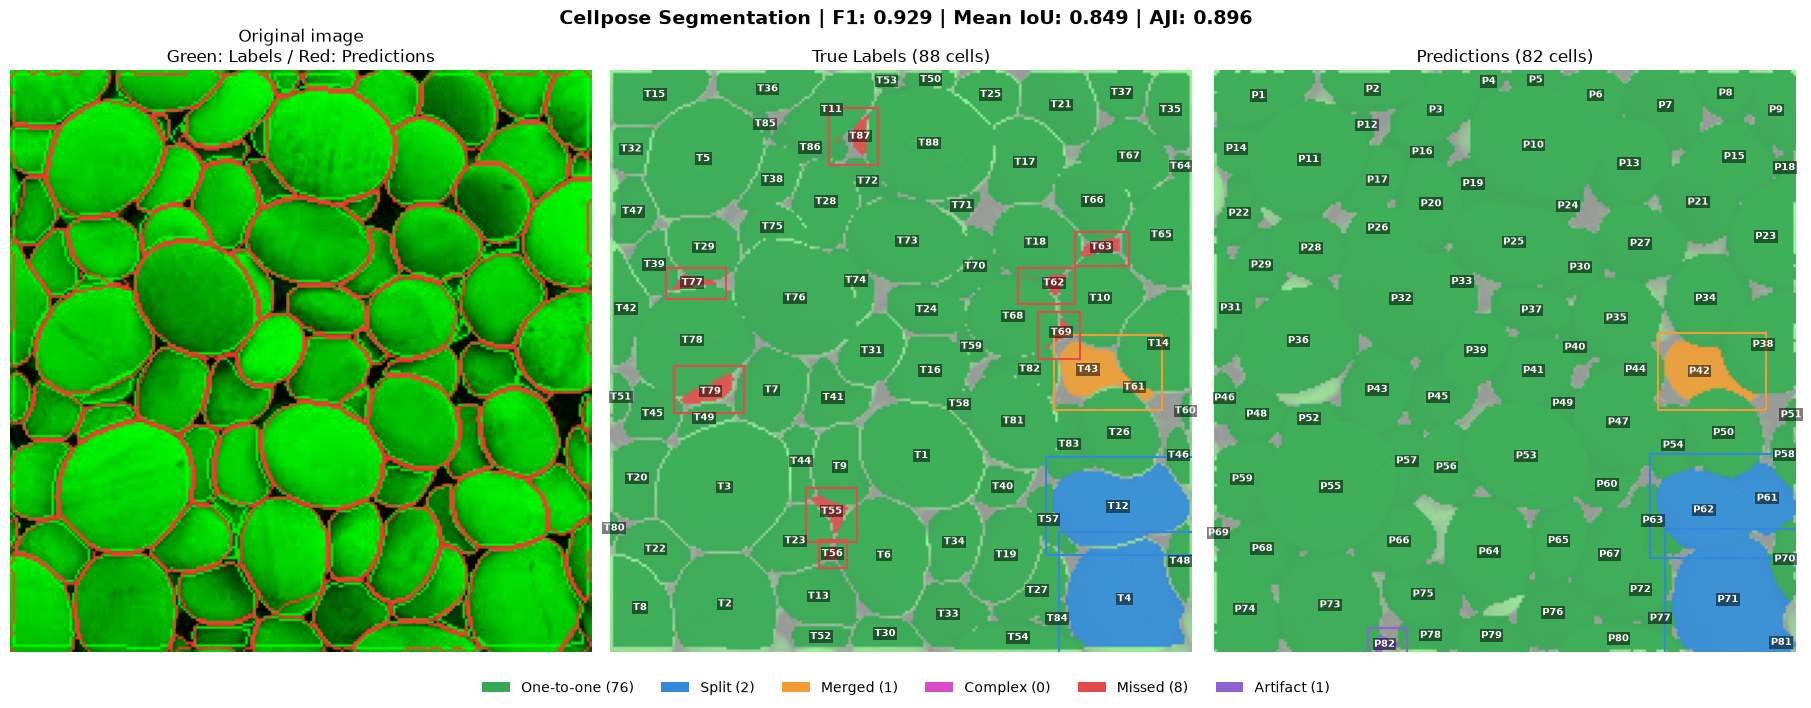

In [8]:
image, true_cells, predicted_cells = inference(
    model=model,
    path_to_image="official_dataset/train/500_img.png",
    path_to_mask="official_dataset/train/500_masks.png"
)

result = map_cell_instances(
    true_cells,
    predicted_cells,
    min_overlap=0.3,
    match_iou=0.5
)

summary = aggregate_cell_results(
    true_cells,
    predicted_cells,
    result,
    image_id="500",
    dataset="official",
    model="cpsam_v2"
)

display(summary.T)

fig, axes = plot_cell_results(
    image,
    true_cells,
    predicted_cells,
    result,
    summary=summary,
    show_ids=True,
    show_boxes=True,
    alpha=0.9,
)

plt.show()

Here is how groups DF looks like:

- all groups are listed in rows
- true ids and predicted ids that are united into a group
- counts of true and predicted ids in the group

In [9]:
display(result['groups'])

,type,true_ids,predicted_ids,n_true,n_predicted
0,matched,[1],[53],1,1
1,matched,[2],[73],1,1
2,matched,[3],[55],1,1
3,split,[4],"[71, 81]",1,2
4,matched,[5],[11],1,1
...,...,...,...,...,...
83,matched,[85],[12],1,1
84,matched,[86],[16],1,1
85,missed,[87],[],1,0
86,matched,[88],[10],1,1


Here is how matches DF looks like:
- Pairs of true cell and predicted cell with their intersection
- Only pairs with enough intersection are shown

In [10]:
display(result['matches'])

,true_id,predicted_id,iou
0,1,53,0.961759
1,2,73,0.923698
2,3,55,0.945024
3,4,71,0.905637
4,5,11,0.943084
...,...,...,...
77,83,54,0.918239
78,84,77,0.703390
79,85,12,0.690909
80,86,16,0.647343


Here is how cells DF looke like:
- Each true cell is in its own row
- Geometrical descriptors of a cell are computed
- What type of group it belongs to (match / merge / split / complex / missed )
- Its best prediction pair (both thresholded and unthreshoded)
- Its best IOU (both thresholded and unthresholded)
- If it is part of True Positives or not

In [11]:
display(result['cells'])

,true_id,pixel_area,min_x,min_y,max_x,max_y,centroid_x,centroid_y,perimeter,eccentricity,...,complex,missed,best_associated_pred_id,best_associated_iou,best_associated_overlap,assigned_pred_id,assigned_iou,is_TP,best_pred_id,best_iou
0,1,1535.0,128,97,169,145,148.448208,119.669707,146.468037,0.608823,...,False,False,53,0.961759,0.983062,53,0.961759,True,53,0.961759
1,2,1277.0,187,24,224,65,205.849648,43.750196,133.840620,0.384293,...,False,False,73,0.923698,0.985904,73,0.923698,True,73,0.923698
2,3,2030.0,136,18,186,69,160.622167,43.487685,167.195959,0.463318,...,False,False,55,0.945024,0.982266,55,0.945024,True,55,0.945024
3,4,1534.0,181,176,223,222,203.885919,198.241851,154.911688,0.399075,...,False,False,71,0.905637,0.963494,71,0.905637,True,71,0.905637
4,5,1589.0,11,13,57,60,33.630585,35.336690,151.539105,0.586092,...,False,False,11,0.943084,0.971627,11,0.943084,True,11,0.943084
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,84,87.0,205,165,222,183,211.563218,172.287356,38.798990,0.673793,...,False,False,77,0.703390,0.954023,77,0.703390,True,77,0.703390
84,85,46.0,16,55,27,68,20.152174,59.347826,28.313708,0.821507,...,False,False,12,0.690909,0.826087,12,0.690909,True,12,0.690909
85,86,183.0,18,62,36,92,29.371585,76.715847,81.633514,0.949191,...,False,False,16,0.647343,0.848101,16,0.647343,True,16,0.647343
86,87,66.0,17,87,33,100,24.954545,95.939394,33.520815,0.826027,...,False,True,<NA>,NaN,NaN,<NA>,NaN,False,3,0.009115


## 8. Collecting Results into Table

My directory looks like:

```output

.
├── preprocessing.ipynb                   # This notebook
│
├── official_dataset/                     # From cellpose.org
│   ├── train/
│   │   ├── 000_img.png
│   │   ├── 000_masks.png
│   │   └── ... (539 more pairs)
│   ├── test/
│   │   ├── 000_img.png
│   │   ├── 000_masks.png
│   │   └── ... (66 more pairs)
│   └── train_cyto2/
│       ├── 540_img.png
│       ├── 540_masks.png
│       └── ... (254 more pairs)
│
├── breast_cancer_cell_dataset/
│   └── training_dataset/
│       ├── training_source/
│       │   ├── cell migration R1 - Position 0_XY1562686096_Z0_T00_C1-1-image1.tif
│       │   └── ... (72 more files)
│       └── training_target/
│           ├── cell migration R1 - Position 0_XY1562686096_Z0_T00_C1-1-image1.tif
│           └── ... (72 more files)
│
├── flow_chamber_dataset/
│   ├── training_dataset/
│   │   ├── FOV2 B0003.tif
│   │   └── ... (57 more files)
│   └── training_target/
│       ├── FOV2 B0003.tif
│       └── ... (57 more files)
│
└── glioma_c6_dataset/
    ├── gen/
    │   ├── anno_gen.json                 # COCO annotations
    │   └── images/
    │       ├── gen_24h_20x_01.tif
    │       └── ... (60 more files)
    └── spec/
        ├── train/
        │   ├── anno_train.json
        │   └── images/
        │       ├── spec_24h_10x_01.tif
        │       └── ... (60 more files)
        ├── test/
        │   ├── anno_test.json
        │   └── images/
        │       ├── spec_24h_10x_31.tif
        │       └── ... (22 more files)
        └── valid/
            ├── anno_valid.json
            └── images/
                ├── spec_24h_10x_42.tif
                └── ... (8 more files)

```

In [13]:
# Define the datasets
DATASETS = [
    'official_dataset/train',
    'official_dataset/test',
    'official_dataset/train_cyto2',
    'breast_cancer_cell_dataset/training_dataset',
    'flow_chamber_dataset/training_dataset',
    # 'glioma_c6_dataset/gen',
    # 'glioma_c6_dataset/spec/train',
    # 'glioma_c6_dataset/spec/test',
    # 'glioma_c6_dataset/spec/valid',
    ]

# Collecting inputs and masks
inputs, masks = [], []
for dataset in DATASETS:

    dataset_path = Path(dataset)

    if dataset in ('official_dataset/train', 'official_dataset/test' , 'official_dataset/train_cyto2'):

        _inputs = [img for img in dataset_path.iterdir() if '_img' in img.name]
        _masks = [dataset_path / img.name.replace('img', 'masks') for img in _inputs]
        

    elif dataset in ('breast_cancer_cell_dataset/training_dataset', 'flow_chamber_dataset/training_dataset'):

        _inputs = [img for img in (dataset_path / 'training_source').iterdir()]
        _masks = [Path(dataset_path, 'training_target', img.name) for img in _inputs]

    elif dataset in ('glioma_c6_dataset/gen', 'glioma_c6_dataset/spec/train', 'glioma_c6_dataset/spec/test', 'glioma_c6_dataset/spec/valid'):

        coco = COCO(str(dataset_path / f'anno_{dataset_path.name}.json'))

        dataset_path = dataset_path / 'images'

        _inputs, _masks = [], []

        for img_id in coco.getImgIds():

            info = coco.loadImgs([img_id])[0]
            filename = dataset_path / Path(info["file_name"])

            mask_path = dataset_path / f"{filename.stem}_masks.tif"
            
            if not mask_path.exists():
                mask = coco_to_instance_mask(coco, img_id)
                tifffile.imwrite(mask_path, mask)

            _inputs.append(filename)
            _masks.append(mask_path)

    else:
        continue

    inputs.extend(_inputs)
    masks.extend(_masks)


RUN_SUMMARY = True

SUMMARY_NAME = "combined_segmentation_quality_v2.csv"
CELL_SUMMARY_NAME = "combined_segmentation_quality_per_cell_v2.csv"
FAILURES = "failed_v2.csv"
MODEL = "cpsam_v2"

if RUN_SUMMARY:

    summaries = []
    cell_summaries = []
    failures = []

    with tqdm(total=len(inputs)) as pbar:

        for input_image, true_mask in zip(inputs, masks):

            try:
                image, true_cells, predicted_cells = inference(
                    model=model,
                    path_to_image=input_image,
                    path_to_mask=true_mask
                )

                result = map_cell_instances(
                    true_cells,
                    predicted_cells,
                    min_overlap=0.3,
                    match_iou=0.5
                )

                image_id = str(input_image)
                dataset = str(input_image.parent)

                summary = aggregate_cell_results(
                    true_cells,
                    predicted_cells,
                    result,
                    image_id=image_id,
                    dataset=dataset,
                    model=MODEL
                )

                image_summary = analyze_image(
                    image=image,
                    true_cells=true_cells,
                    image_id=image_id,
                    dataset=dataset
                )

                combined = pd.concat([summary, image_summary.drop(columns=["image_id", "dataset"])], axis=1)

                cells = result["cells"].copy()
                cells["image_id"] = image_id
                cells["dataset"] = dataset
                cells["model"] = MODEL

                combined.to_csv(SUMMARY_NAME, mode="a", header=not Path(SUMMARY_NAME).exists(), index=False)
                cells.to_csv(CELL_SUMMARY_NAME, mode="a", header=not Path(CELL_SUMMARY_NAME).exists(), index=False)

            except Exception as e:
                failures.append({"image_id": str(input_image), "mask_path": str(true_mask), "error_type": type(e).__name__, "error": str(e)})

            finally:
                pbar.update(1)


    failures_df = pd.DataFrame(failures, columns=["image_id", "mask_path", "error_type", "error"])
    failures_df.to_csv(FAILURES, index=False)
    print(f"Failed: {len(failures_df)}")



100%|██████████| 993/993 [4:02:32<00:00, 14.66s/it]    

Failed: 0


## 9. Final Tables

In [16]:
import pandas as pd
final_table = pd.read_csv('combined_segmentation_quality_v2.csv').reset_index(drop=True)
display(final_table)

,image_id,dataset,model,n_true,n_predicted,count_error,TP,FP,FN,precision,...,intensity_p99,contrast,laplacian_variance,noise_estimate,n_cells,cell_density,foreground_fraction,mean_cell_area,median_cell_area,cell_area_cv
0,official_dataset/train/164_img.png,official_dataset/train,cpsam_v2,23,23,0,23,0,0,1.000000,...,8822.707031,8822.707031,0.000413,0.005038,23,117.596531,0.096623,821.652174,797.0,0.406147
1,official_dataset/train/174_img.png,official_dataset/train,cpsam_v2,28,27,-1,25,2,3,0.925926,...,21321.542969,21138.451767,0.000495,0.006189,28,106.811523,0.149349,1398.250000,1412.5,0.499343
2,official_dataset/train/202_img.png,official_dataset/train,cpsam_v2,87,88,1,79,9,8,0.897727,...,35842.250000,34371.798828,0.003199,0.017183,87,465.539384,0.379613,815.425287,823.0,0.349453
3,official_dataset/train/212_img.png,official_dataset/train,cpsam_v2,142,141,-1,138,3,4,0.978723,...,40253.601562,40253.601562,0.007260,0.022528,142,747.557278,0.505744,676.528169,663.0,0.569253
4,official_dataset/train/457_img.png,official_dataset/train,cpsam_v2,86,82,-4,79,3,7,0.963415,...,37312.699219,33452.764893,0.006454,0.021545,86,1006.554307,0.939478,933.360465,891.0,0.709865
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
988,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2,60,68,8,60,8,0,0.882353,...,13318.000000,3739.000000,0.000156,0.002849,60,30.612245,0.024161,789.250000,758.0,0.263644
989,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2,47,53,6,47,6,0,0.886792,...,13302.000000,3666.000000,0.000152,0.002752,47,23.979592,0.017869,745.191489,757.0,0.300658
990,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2,92,102,10,91,11,1,0.892157,...,13513.000000,7081.000000,0.000165,0.003170,92,46.938776,0.033780,719.663043,697.0,0.317847
991,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2,46,55,9,46,9,0,0.836364,...,13299.000000,3689.000000,0.000152,0.002735,46,23.469388,0.017001,724.391304,671.0,0.331508


COLUMNS:

1. Metadata

| Column | Description |
|---------|-----------|
| image_id	| Image identifier (path to the input file).| 
| dataset	| Stem of the dataset.| 
| model	| cyto3 / cpsam_v2| 

2. Detection Quality Metrics

| Column	| Description| 
|-----------|------------|
| n_true	| Number of true cells.| 
| n_predicted	| Number of predicted cell.| 
| count_error	| n_predicted - n_true | 
| TP	| True positives: one-to-one matches. | 
| FP	| False positives: predicted cells that have no match among true cells. | 
| FN	| False negatives: true cells with no match among predicted cells. | 
| precision	| TP / (TP + FP) | 
| recall	| TP / (TP + FN) | 
| f1	| harmonic mean of precision and recall.| 

3. Average Precision and Boundaries

| Column    |Description |
|-----------|------------|
| ap50	| Official average precision at iou >= 0.50 | 
| ap75	| Official average precision at iou >= 0.75 | 
| ap90	| Official average precision at iou >= 0.90 | 
| b_prec_50	| Boundary pixel precision at tolerance 0.50 | 
| b_prec_75	| Boundary pixel precision at tolerance 0.75 | 
| b_prec_90	| Boundary pixel precision at tolerance 0.90  | 
| b_rec_50	| Boundary pixel recall at tolerance 0.50 | 
| b_rec_75	| Boundary pixel recall at tolerance 0.75.| 
| b_rec_90	| Boundary pixel recall at tolerance 0.90.| 
| b_f1_50	| Boundary pixel f1 at tolerance 0.50 | 
| b_f1_75	| Boundary pixel f1 at tolerance 0.75.| 
| b_f1_90	| Boundary pixel f1 at tolerance 0.90.| 

4. Segmentation Quality Metrics

| Column	| Description| 
|---------|-----------|
| mean_iou	| Mean Jaccard of matched cell pairs. | 
| median_iou	| Median Jaccard of matched cell pairs. | 
| mean_dice | Mean Dice similarity of matched cell pairs. | 
| foreground_iou	| Pixel-wise Jaccard of foreground pixels (regardless matching).| 
| foreground_dice	| Pixel-wise Dice similarity of foreground pixels (regardless matching). | 
| aji_custom	| Aggregated Jaccard Index - total intersection divided but total union for thresholded matches. | 
| aji_official	| Official Aggregated Jaccard Index - no threshold appied | 

5. Error Categories

(Extracted form bipartite graph)

| Column	| Description| 
|---------|-----------|
| n_matched_groups	| Number of exactly matching pairs.| 
| n_split_groups	| Number of true cells split in the prediction.| 
| n_merged_groups	| Number of true cells merged in the prediction.| 
| n_complex_groups	| Number of complex cases - not match / split / merge, etc.| 
| n_missed_groups	| Number of true cells missing in the prediction. | 
| n_artifact_groups	| Number of predicted cells that has no corresponding true cells. | 

6. Input Image Format

| Column	| Description| 
|---------|-----------|
| height	| Image height (pixels) | 
| width	| Image width (pixels) | 
| aspect_ratio	| width / height | 
| n_pixels	| height × width | 
| channels	| 1 for grayscale, 3 for RGB | 
| dtype	| NumPy data type (uint8 or uint16, etc.)| 
| bit_depth	| Bits per channel (usually 8 or 16) | 

7. Input Image Properties

Calculated from grayscale version (if RGB - converted to grayscale).

| Column	| Description| 
|---------|-----------|
| intensity_mean	| Mean intensity across pixels.| 
| intensity_std	| Std of intensities.| 
| intensity_p01	| 1st percentile of intensity.| 
| intensity_p99	| 99th percentile of intensity.| 
| contrast	| 99th - 1st percentiles.| 
| laplacian_variance	| Variance of the Laplacian normalized (sharpness).| 
| noise_estimate	| Std between intesities and gaussian blurred intesities. | 

8. True Mask Properties

Calculated only from the masks from datasets, not from the predictions.

| Column	| Description| 
|---------|-----------|
| n_cells	| = n_true| 
| cell_density	| n_cells / n_pixels × 10^6 | 
| foreground_fraction	| Fraction of non-background pixels. | 
| mean_cell_area	| Mean area of a cell (pixels). | 
| median_cell_area	| Median area of a cell (pixels). | 
| cell_area_cv	| std of areas / mean of areas | 


In [19]:
final_cell_table = pd.read_csv('combined_segmentation_quality_per_cell_v2.csv').reset_index(drop=True)
display(final_cell_table)

,true_id,pixel_area,min_x,min_y,max_x,max_y,centroid_x,centroid_y,perimeter,eccentricity,...,best_associated_iou,best_associated_overlap,assigned_pred_id,assigned_iou,is_TP,best_pred_id,best_iou,image_id,dataset,model
0,1,1169.0,92,180,132,223,110.111206,198.530368,140.568542,0.681476,...,0.833471,0.958294,1.0,0.833471,True,1,0.833471,official_dataset/train/164_img.png,official_dataset/train,cpsam_v2
1,2,540.0,90,222,124,246,105.068519,232.940741,99.112698,0.851400,...,0.777583,0.934737,2.0,0.777583,True,2,0.777583,official_dataset/train/164_img.png,official_dataset/train,cpsam_v2
2,3,1382.0,169,152,215,196,192.824891,171.254703,148.260931,0.712227,...,0.834483,0.946792,11.0,0.834483,True,11,0.834483,official_dataset/train/164_img.png,official_dataset/train,cpsam_v2
3,4,1145.0,213,136,248,188,230.144105,162.530131,148.367532,0.839799,...,0.826733,0.937325,18.0,0.826733,True,18,0.826733,official_dataset/train/164_img.png,official_dataset/train,cpsam_v2
4,5,643.0,237,119,265,151,252.143079,134.024883,100.526912,0.758760,...,0.815977,0.907937,21.0,0.815977,True,21,0.815977,official_dataset/train/164_img.png,official_dataset/train,cpsam_v2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145526,43,953.0,36,1177,74,1212,53.651626,1193.780693,115.639610,0.348415,...,0.899699,0.953241,2.0,0.899699,True,2,0.899699,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2
145527,44,998.0,97,1168,135,1201,116.014028,1184.186373,115.740115,0.512671,...,0.897205,0.996994,5.0,0.897205,True,5,0.897205,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2
145528,45,472.0,165,1359,188,1385,175.627119,1370.506356,78.769553,0.484511,...,0.917339,0.963983,7.0,0.917339,True,7,0.917339,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2
145529,46,697.0,128,1369,158,1400,142.210904,1382.505022,96.911688,0.379452,...,0.853760,0.966877,6.0,0.853760,True,6,0.853760,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2


1. Metadata

| Column | Description |
|---------|-----------|
| image_id	| Image identifier (path to the input file).| 
| dataset	| Stem of the dataset.| 
| model	| cyto3 / cpsam_v2| 

2. Cell Shapes

| Column  | Description |
|---------|-----------|
| true_id	| True cell identifier in its image |
| pixel_area	| Area in pixels |
| min_x	| Bounding box min_x |
| min_y	| Bounding box min_y |
| max_x	| Bounding box max_x |
| max_y	| Bounding box max_y |
| centroid_x	| Cell's centroid (x) |
| centroid_y	| Cell's centroid (y) |
| perimeter	| Estimated boundary length in pixels |
| eccentricity	| Elongation of fitted ellipse (from 0 to 1) |
| solidity	| Area divided by convex hull area (compactness) |
| extent	| Area divided by bounding box area |
| orientation	| Angle of the major axis |
| major_axis_length	| Length of the major axis |
| minor_axis_length	| Length of the minor axis |
| equivalent_diameter	| Pseudo-diameter (if cell was an ideal circle) |
| aspect_ratio	| major_axis_length / minor_axis_length |
| circularity	| 4 pi * pixel_area / perimeter^2 |
| pseudo_radius	| Pseudo-radius (if cell was an ideal circle) |

3. Groups Association

| Column  | Description |
|---------|-----------|
| group_id	| Identifier of the group within instance | 
| group_type	| matched, split, merged, complex, or missed | 
| associated_pred_ids	| Predicted cell IDs associated with the true cell | 
| n_associated_pred	| Count of associated predicted cells | 
| n_associated_true	| Number of true cells in the same component | 
| matched	| Boolean | 
| split	| Boolean | 
| merged	| Boolean | 
| complex	| Boolean | 
| missed	| Boolean | 

4. Extact Matching

| Column  | Description |
|---------|-----------|
| best_associated_pred_id	| ID of the best IoU prediction | 
| best_associated_iou	| IOU with the best-associated predicted cell | 
| best_associated_overlap	| Overlap with the best-associated predicted cell | 
| assigned_pred_id	| ID of redicted cell assigned by optimization | 
| assigned_iou	| IOU with the assigned prediction | 
| is_TP	| Boolean | 
| best_pred_id	| ID of the predicted cell with the highest iou | 
| best_iou	| Maximum iou with any predicted cell | 
